# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

In [5]:
df = pd.read_csv('/content/drive/MyDrive/ANALYTICS/Colaboratory/data/House_Rent_Dataset.csv')

In [6]:
print("Розмір датасету")
print(f"Рядків: {df.shape[0]}, Стовпців: {df.shape[1]}")

print("Перші 5 рядків датасету")
print(df.head())

print("Загальна інформація про дані")
print(df.info())

Розмір датасету
Рядків: 4746, Стовпців: 12
Перші 5 рядків датасету
    Posted On  BHK   Rent  Size            Floor    Area Type  \
0  2022-05-18    2  10000  1100  Ground out of 2   Super Area   
1  2022-05-13    2  20000   800       1 out of 3   Super Area   
2  2022-05-16    2  17000  1000       1 out of 3   Super Area   
3  2022-07-04    2  10000   800       1 out of 2   Super Area   
4  2022-05-09    2   7500   850       1 out of 2  Carpet Area   

              Area Locality     City Furnishing Status  Tenant Preferred  \
0                    Bandel  Kolkata       Unfurnished  Bachelors/Family   
1  Phool Bagan, Kankurgachi  Kolkata    Semi-Furnished  Bachelors/Family   
2   Salt Lake City Sector 2  Kolkata    Semi-Furnished  Bachelors/Family   
3               Dumdum Park  Kolkata       Unfurnished  Bachelors/Family   
4             South Dum Dum  Kolkata       Unfurnished         Bachelors   

   Bathroom Point of Contact  
0         2    Contact Owner  
1         1    Contact 

## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


Аналіз пропущених значень
                   Кількість пропусків  Відсоток (%)
Posted On                            0           0.0
BHK                                  0           0.0
Rent                                 0           0.0
Size                                 0           0.0
Floor                                0           0.0
Area Type                            0           0.0
Area Locality                        0           0.0
City                                 0           0.0
Furnishing Status                    0           0.0
Tenant Preferred                     0           0.0
Bathroom                             0           0.0
Point of Contact                     0           0.0
Базова статистика
               BHK          Rent         Size     Bathroom
count  4746.000000  4.746000e+03  4746.000000  4746.000000
mean      2.083860  3.499345e+04   967.490729     1.965866
std       0.832256  7.810641e+04   634.202328     0.884532
min       1.000000  1.200000e+0

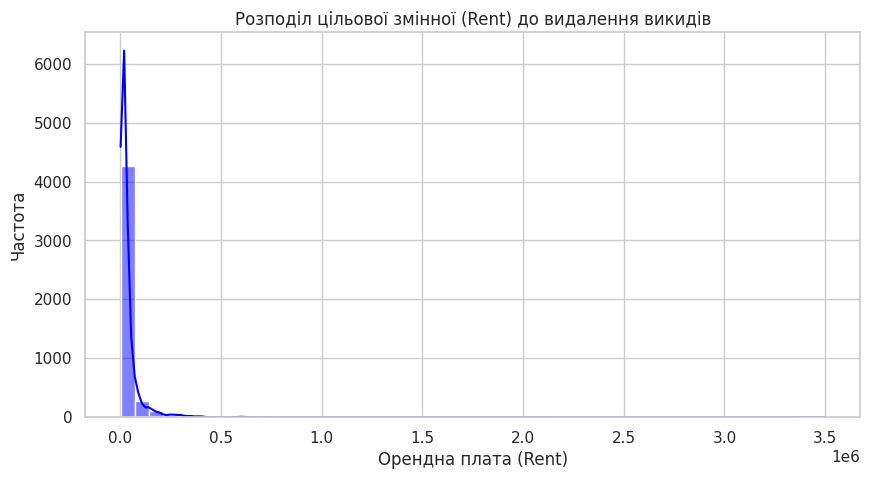

Робота з викидами
Знайдено викидів: 520 з 4746 рядків
Розмір датасету після видалення викидів: (4226, 12)


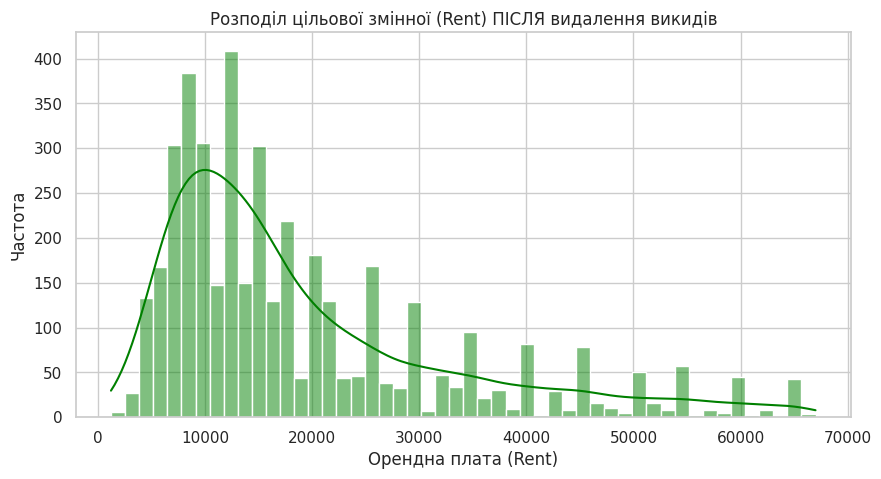

Кількість унікальних значень категоріальних колонок
Колонка 'Posted On': 80 унікальних значень
Колонка 'Floor': 340 унікальних значень
Колонка 'Area Type': 3 унікальних значень
Колонка 'Area Locality': 1997 унікальних значень
Колонка 'City': 6 унікальних значень
Колонка 'Furnishing Status': 3 унікальних значень
Колонка 'Tenant Preferred': 3 унікальних значень
Колонка 'Point of Contact': 3 унікальних значень


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Аналіз пропущених значень")
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_data = pd.DataFrame({'Кількість пропусків': missing_count, 'Відсоток (%)': missing_percent})
print(missing_data)

print("Базова статистика")
print(df.describe())

plt.figure(figsize=(10, 5))
sns.histplot(df['Rent'], bins=50, kde=True, color='blue')
plt.title('Розподіл цільової змінної (Rent) до видалення викидів')
plt.xlabel('Орендна плата (Rent)')
plt.ylabel('Частота')
plt.show()

print("Робота з викидами")
Q1 = df['Rent'].quantile(0.25)
Q3 = df['Rent'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Rent'] < lower_bound) | (df['Rent'] > upper_bound)]
print(f"Знайдено викидів: {len(outliers)} з {len(df)} рядків")

df_clean = df[(df['Rent'] >= lower_bound) & (df['Rent'] <= upper_bound)]
print(f"Розмір датасету після видалення викидів: {df_clean.shape}")

plt.figure(figsize=(10, 5))
sns.histplot(df_clean['Rent'], bins=50, kde=True, color='green')
plt.title('Розподіл цільової змінної (Rent) ПІСЛЯ видалення викидів')
plt.xlabel('Орендна плата (Rent)')
plt.ylabel('Частота')
plt.show()

print("Кількість унікальних значень категоріальних колонок")
categorical_cols = df_clean.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    unique_count = df_clean[col].nunique()
    print(f"Колонка '{col}': {unique_count} унікальних значень")



## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


Матриця кореляцій
               BHK      Rent      Size  Bathroom
BHK       1.000000  0.401268  0.698453  0.747918
Rent      0.401268  1.000000  0.393605  0.506528
Size      0.698453  0.393605  1.000000  0.680607
Bathroom  0.747918  0.506528  0.680607  1.000000


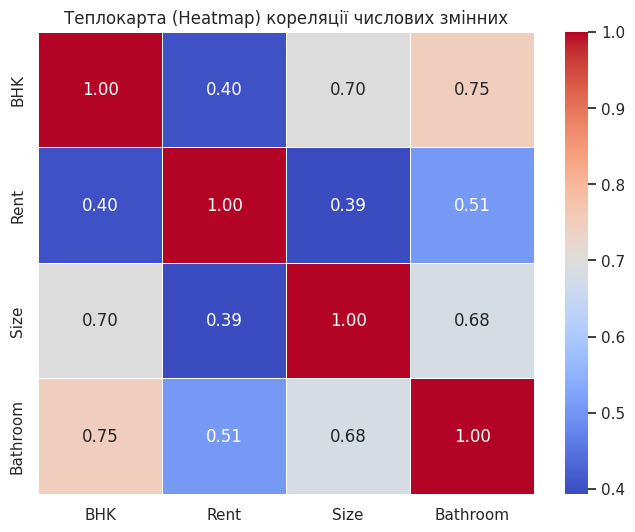

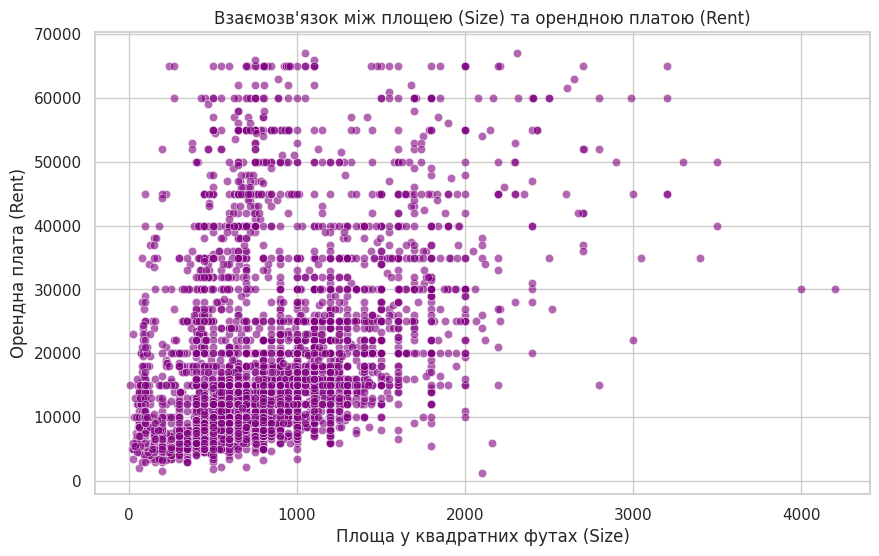

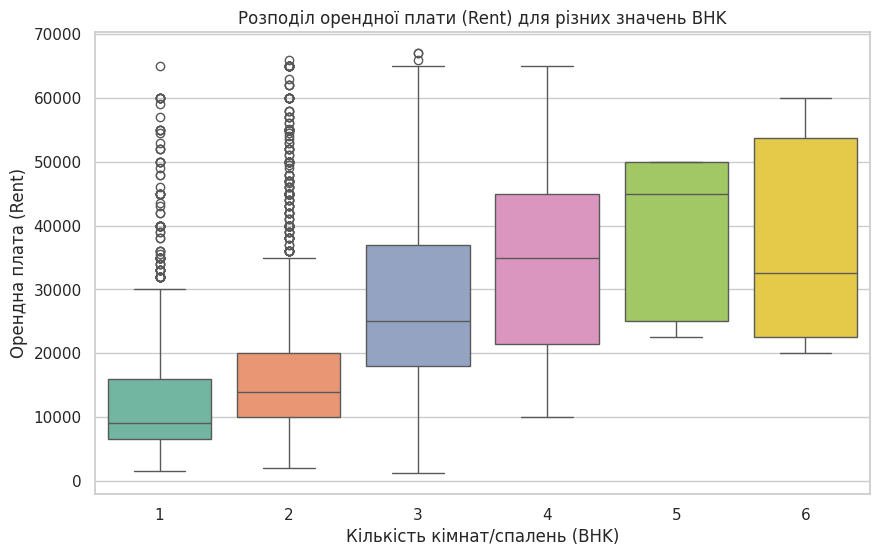

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Матриця кореляцій")
numeric_df = df_clean.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_df.corr()
print(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Теплокарта (Heatmap) кореляції числових змінних')
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='Size', y='Rent', alpha=0.6, color='purple')
plt.title('Взаємозв\'язок між площею (Size) та орендною платою (Rent)')
plt.xlabel('Площа у квадратних футах (Size)')
plt.ylabel('Орендна плата (Rent)')
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='BHK', y='Rent', hue='BHK', palette='Set2', legend=False)
plt.title('Розподіл орендної плати (Rent) для різних значень BHK')
plt.xlabel('Кількість кімнат/спалень (BHK)')
plt.ylabel('Орендна плата (Rent)')
plt.show()


## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df_ml = df_clean.copy()

df_ml['Size_per_BHK'] = df_ml['Size'] / df_ml['BHK']

df_ml['Bath_to_BHK_ratio'] = df_ml['Bathroom'] / df_ml['BHK']

columns_to_drop = ['Area Locality', 'Point of Contact']
df_ml = df_ml.drop(columns=columns_to_drop, errors='ignore')

categorical_cols = df_ml.select_dtypes(include=['object', 'category']).columns

df_ml = pd.get_dummies(df_ml, columns=categorical_cols, drop_first=True)

X = df_ml.drop(columns=['Rent'])
y = df_ml['Rent']

numeric_features = ['Size', 'BHK', 'Bathroom', 'Size_per_BHK', 'Bath_to_BHK_ratio']

scaler = StandardScaler()

X[numeric_features] = scaler.fit_transform(X[numeric_features])

print("Підготовка даних завершена")
print(f"Розмір матриці ознак X: {X.shape}")
print(f"Розмір вектора цільової змінної y: {y.shape}")
print("\nПерші 3 рядки обробленої матриці ознак (X):")
print(X.head(3))


Підготовка даних завершена
Розмір матриці ознак X: (4226, 434)
Розмір вектора цільової змінної y: (4226,)

Перші 3 рядки обробленої матриці ознак (X):
        BHK      Size  Bathroom  Size_per_BHK  Bath_to_BHK_ratio  \
0  0.052966  0.469859  0.272578      0.604132           0.147328   
1  0.052966 -0.147778 -1.133910     -0.268747          -1.637671   
2  0.052966  0.263980 -1.133910      0.313173          -1.637671   

   Posted On_2022-04-24  Posted On_2022-04-25  Posted On_2022-04-26  \
0                 False                 False                 False   
1                 False                 False                 False   
2                 False                 False                 False   

   Posted On_2022-04-27  Posted On_2022-04-28  ...  Area Type_Super Area  \
0                 False                 False  ...                  True   
1                 False                 False  ...                  True   
2                 False                 False  ...             

## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [26]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()

model.fit(X_train, y_train)

print("Коефіцієнти (ваги) моделі")
coefficients = pd.DataFrame({
    'Ознака': X.columns,
    'Коефіцієнт (вага)': model.coef_
})

coefficients['Абсолютне значення'] = coefficients['Коефіцієнт (вага)'].abs()
coefficients_sorted = coefficients.sort_values(by='Абсолютне значення', ascending=False)

print(coefficients_sorted[['Ознака', 'Коефіцієнт (вага)']].head(10))

top_2_features = coefficients_sorted['Ознака'].iloc[:2].tolist()
print(f"2 ознаки, які найбільше впливають на прогноз: {top_2_features[0]} та {top_2_features[1]}")

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Прогнозування завершено")
print(f"Зроблено прогнозів для тренувальної вибірки: {len(y_train_pred)}")
print(f"Зроблено прогнозів для тестової вибірки: {len(y_test_pred)}")


Коефіцієнти (ваги) моделі
                 Ознака  Коефіцієнт (вага)
258  Floor_25 out of 35       39058.219988
391    Floor_9 out of 9       35781.558777
262  Floor_26 out of 44       35043.285112
252  Floor_23 out of 35       34670.142437
253  Floor_23 out of 40       34338.576740
372   Floor_8 out of 58       34276.325215
333   Floor_6 out of 18       33757.400477
140  Floor_12 out of 14       33705.747659
299   Floor_4 out of 31       33602.687066
198  Floor_16 out of 38       31779.241656
2 ознаки, які найбільше впливають на прогноз: Floor_25 out of 35 та Floor_9 out of 9
Прогнозування завершено
Зроблено прогнозів для тренувальної вибірки: 3380
Зроблено прогнозів для тестової вибірки: 846


## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


Метрики якості моделі
                Метрика  Навчальна вибірка  Тестова вибірка
                    MAE        4960.291915      6317.190188
                   RMSE        7016.681249      9188.800781
R² (Коеф. детермінації)           0.742116         0.559646


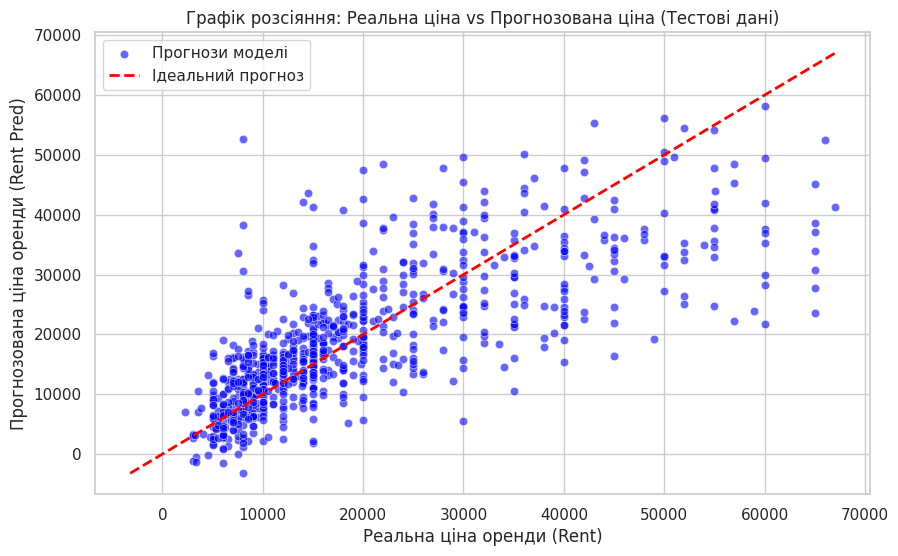

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_train = mean_absolute_error(y_train, y_train_pred)
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
r2_train = r2_score(y_train, y_train_pred)

mae_test = mean_absolute_error(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
r2_test = r2_score(y_test, y_test_pred)

metrics_df = pd.DataFrame({
    'Метрика': ['MAE', 'RMSE', 'R² (Коеф. детермінації)'],
    'Навчальна вибірка': [mae_train, rmse_train, r2_train],
    'Тестова вибірка': [mae_test, rmse_test, r2_test]
})

print("Метрики якості моделі")
print(metrics_df.to_string(index=False))

plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.6, color='blue', label='Прогнози моделі')

max_val = max(y_test.max(), y_test_pred.max())
min_val = min(y_test.min(), y_test_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ідеальний прогноз')

plt.title('Графік розсіяння: Реальна ціна vs Прогнозована ціна (Тестові дані)')
plt.xlabel('Реальна ціна оренди (Rent)')
plt.ylabel('Прогнозована ціна оренди (Rent Pred)')
plt.legend()
plt.grid(True)
plt.show()


## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

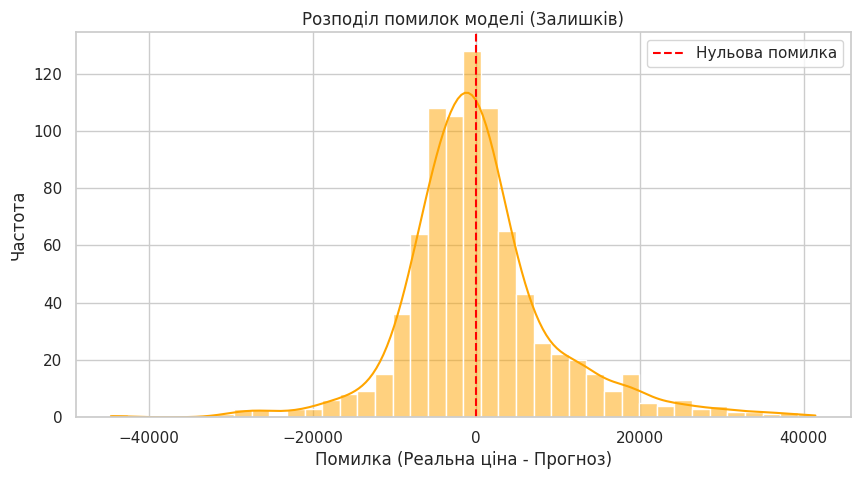

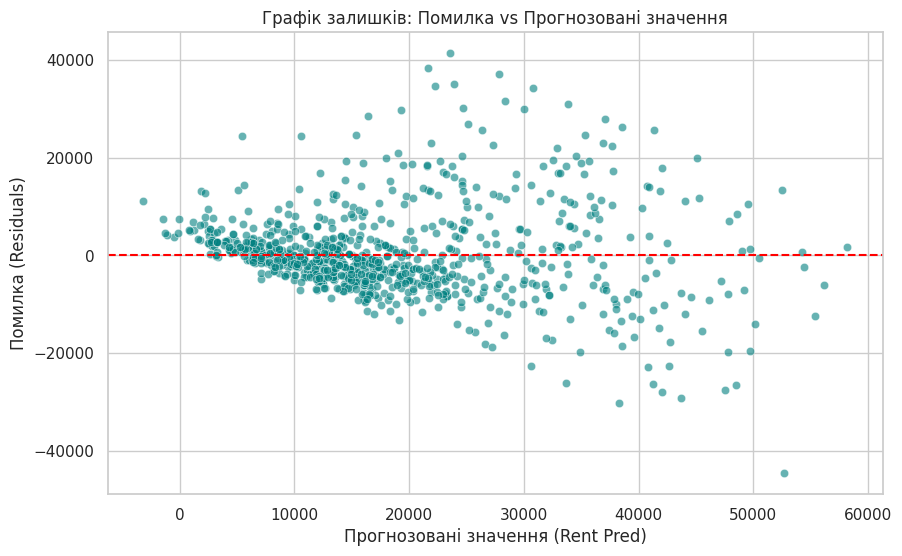

ТОП-5 прогнозів з найбільшими помилками
      Реальна ціна       Прогноз  Помилка (Залишок)  BHK     City
549           8000  52647.477787      -44647.477787    2   Mumbai
3520         65000  23549.242831       41450.757169    3  Chennai
809          60000  21663.805320       38336.194680    1   Mumbai
570          65000  27839.176774       37160.823226    2   Mumbai
954          59000  23926.516687       35073.483313    1   Mumbai
Середня абсолютна помилка за містами
City
Mumbai       11710.774825
Delhi         7243.201511
Hyderabad     5772.110276
Chennai       5329.997327
Bangalore     4830.445392
Kolkata       4384.870107
Name: Абсолютна помилка, dtype: float64

ередня абсолютна помилка за кількістю кімнат (BHK)
BHK
4    12602.917861
3     9366.267133
6     6134.556217
5     6131.189926
2     5743.175353
1     4926.747677
Name: Абсолютна помилка, dtype: float64


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

residuals = y_test - y_test_pred

analysis_df = pd.DataFrame({
    'Реальна ціна': y_test,
    'Прогноз': y_test_pred,
    'Помилка (Залишок)': residuals,
    'Абсолютна помилка': residuals.abs()
})

analysis_df['BHK'] = df_clean.loc[X_test.index, 'BHK']
analysis_df['City'] = df_clean.loc[X_test.index, 'City']

plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=40, kde=True, color='orange')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Нульова помилка')
plt.title('Розподіл помилок моделі (Залишків)')
plt.xlabel('Помилка (Реальна ціна - Прогноз)')
plt.ylabel('Частота')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.6, color='teal')
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)
plt.title('Графік залишків: Помилка vs Прогнозовані значення')
plt.xlabel('Прогнозовані значення (Rent Pred)')
plt.ylabel('Помилка (Residuals)')
plt.grid(True)
plt.show()

print("ТОП-5 прогнозів з найбільшими помилками")
top_5_errors = analysis_df.sort_values(by='Абсолютна помилка', ascending=False).head(5)
print(top_5_errors[['Реальна ціна', 'Прогноз', 'Помилка (Залишок)', 'BHK', 'City']])

print("Середня абсолютна помилка за містами")
city_error = analysis_df.groupby('City')['Абсолютна помилка'].mean().sort_values(ascending=False)
print(city_error)
print("\nередня абсолютна помилка за кількістю кімнат (BHK)")
bhk_error = analysis_df.groupby('BHK')['Абсолютна помилка'].mean().sort_values(ascending=False)
print(bhk_error)
